In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
df = pd.read_csv(url)

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


Understand the dataset's size, columns, data types and missing values before building a machine-learning model.

In [2]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (6433, 14)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 703.7+ KB

Missing values:
pickup              0
dropoff

Understand the average, minimum, maximum and distribution of taxi fares, distances and other features.

In [3]:
# Statistics for numerical columns
display(df.describe())

# Statistics for categorical columns
display(df.describe(include=["object"]))

,passengers,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
std,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570
min,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000


,pickup,dropoff,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
count,6433,6433,6433,6389,6407,6388,6407,6388
unique,6414,6425,2,2,194,203,4,5
top,2019-03-13 10:57:06,2019-03-04 18:08:13,yellow,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan
freq,2,2,5451,4577,230,245,5268,5206


Understand how taxi fares relate to trip distance.

In [5]:
%pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.8 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 11.3 MB/s eta 0:00:00
  Using cached numpy-2.5.5-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 53.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 31.1 MB/s eta 0:00:00:00:010:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following

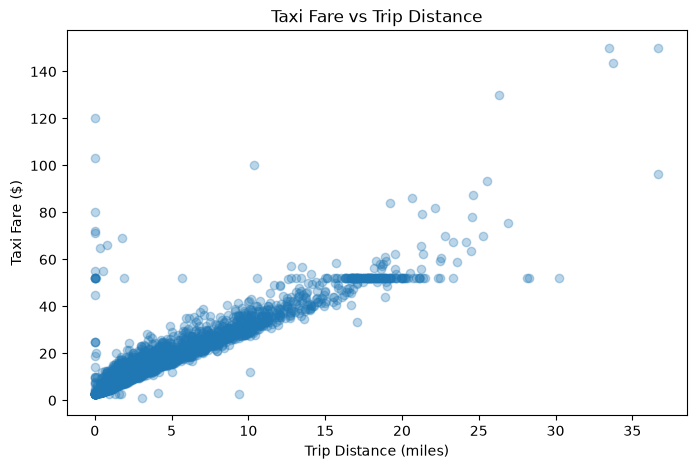

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["distance"], df["fare"], alpha=0.3)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Taxi Fare ($)")
plt.title("Taxi Fare vs Trip Distance")
plt.show()

which taxi fares are most common and identify unusually expensive trips.

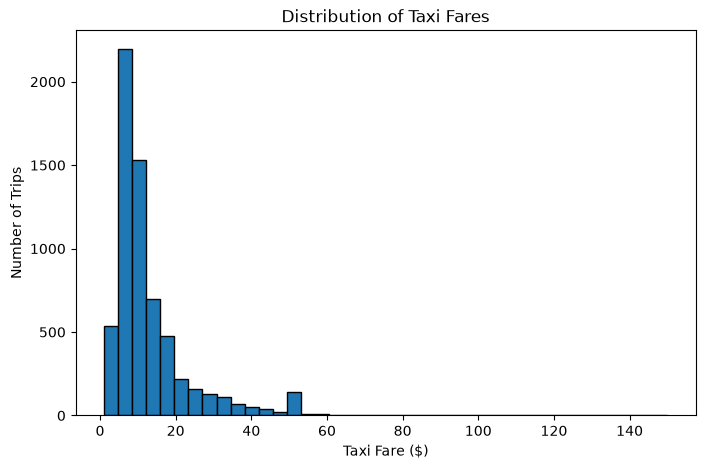

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["fare"], bins=40, edgecolor="black")

plt.xlabel("Taxi Fare ($)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Taxi Fares")

plt.show()

Most taxi fares are between $5 and $20.
Expensive trips are less common.
The distribution is right-skewed, meaning a few trips have unusually high fares

dentify which payment method passengers use most frequently.

In [8]:
df["payment"].value_counts()

payment
credit card    4577
cash           1812
Name: count, dtype: int64

Find missing data that could affect the accuracy of our machine-learning model.

In [9]:
# Calculate percentage of missing values
df.isna().mean().sort_values(ascending=False) * 100

dropoff_zone       0.699518
dropoff_borough    0.699518
payment            0.683973
pickup_zone        0.404166
pickup_borough     0.404166
pickup             0.000000
tip                0.000000
fare               0.000000
distance           0.000000
passengers         0.000000
dropoff            0.000000
color              0.000000
tolls              0.000000
total              0.000000
dtype: float64

dropoff_zone and dropoff_borough: 0.70% missing.
payment: 0.68% missing.
pickup_zone and pickup_borough: 0.40% missing.
All other columns: No missing values.

Replace missing categorical values so our machine-learning model can process the data.

In [10]:
from sklearn.impute import SimpleImputer

categorical_cols = [
    "pickup_zone",
    "pickup_borough",
    "dropoff_zone",
    "dropoff_borough",
    "payment"
]

imputer = SimpleImputer(strategy="most_frequent")

df[categorical_cols] = imputer.fit_transform(df[categorical_cols])

print(df[categorical_cols].isna().sum())

pickup_zone        0
pickup_borough     0
dropoff_zone       0
dropoff_borough    0
payment            0
dtype: int64


Transform trip distance to reduce the effect of unusually long journeys on our machine-learning model.

In [11]:
df["log_distance"] = np.log1p(df["distance"])

df[["distance", "log_distance"]].head()

,distance,log_distance
0,1.60,0.955511
1,0.79,0.582216
2,1.37,0.862890
3,7.70,2.163323
4,2.16,1.150572


Group taxi journeys into distance ranges to help the model recognise short and long trips.

In [12]:
df["distance_bucket"] = pd.cut(
    df["distance"],
    bins=[0, 2, 5, 10, 20, 50],
    labels=False
)

df[["distance", "distance_bucket"]].head()

,distance,distance_bucket
0,1.60,0.0
1,0.79,0.0
2,1.37,0.0
3,7.70,2.0
4,2.16,1.0


Extract useful information from pickup and drop-off times to help predict taxi fares.

In [13]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

df["duration_minutes"] = (
    df["dropoff"] - df["pickup"]
).dt.total_seconds() / 60

df["hour"] = df["pickup"].dt.hour
df["pickup_day_of_week"] = df["pickup"].dt.dayofweek

df[["duration_minutes", "hour", "pickup_day_of_week"]].head()

,duration_minutes,hour,pickup_day_of_week
0,6.250000,20,5
1,7.083333,16,0
2,7.400000,17,2
3,25.866667,1,6
4,9.533333,13,5


Extract useful information from pickup and drop-off times to help predict taxi fares.

In [14]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

df["duration_minutes"] = (
    df["dropoff"] - df["pickup"]
).dt.total_seconds() / 60

df["hour"] = df["pickup"].dt.hour
df["pickup_day_of_week"] = df["pickup"].dt.dayofweek

df[["duration_minutes", "hour", "pickup_day_of_week"]].head()

,duration_minutes,hour,pickup_day_of_week
0,6.250000,20,5
1,7.083333,16,0
2,7.400000,17,2
3,25.866667,1,6
4,9.533333,13,5


duration_minutes: How long each taxi trip lasted.
hour: Pickup hour (0–23).
pickup_day_of_week: Monday = 0, Sunday = 6.

Group pickup times into morning, afternoon, evening and night to help the model recognise travel patterns.

In [15]:
df["time_bin"] = pd.cut(
    df["hour"],
    bins=[0, 6, 12, 18, 24],
    labels=["Night", "Morning", "Afternoon", "Evening"],
    right=False
)

df[["hour", "time_bin"]].head()

,hour,time_bin
0,20,Evening
1,16,Afternoon
2,17,Afternoon
3,1,Night
4,13,Afternoon


The categories are:
- Night: 00:00–05:59
- Morning: 06:00–11:59
- Afternoon: 12:00–17:59
- Evening: 18:00–23:59

Combine pickup location and time of day to help the model identify patterns in taxi fares.

In [16]:
df["borough_time"] = (
    df["pickup_borough"].astype(str)
    + "_"
    + df["time_bin"].astype(str)
)

df[["pickup_borough", "time_bin", "borough_time"]].head()

,pickup_borough,time_bin,borough_time
0,Manhattan,Evening,Manhattan_Evening
1,Manhattan,Afternoon,Manhattan_Afternoon
2,Manhattan,Afternoon,Manhattan_Afternoon
3,Manhattan,Night,Manhattan_Night
4,Manhattan,Afternoon,Manhattan_Afternoon


Select the information our model will use to predict taxi fares.

In [17]:
y = df["fare"]

raw_features = [
    "distance", "passengers", "tolls", "tip",
    "hour", "pickup_day_of_week",
    "color", "payment", "pickup_zone",
    "dropoff_zone", "pickup_borough", "dropoff_borough"
]

X_raw = df[raw_features].copy()

print("Features shape:", X_raw.shape)
print("Target shape:", y.shape)

Features shape: (6433, 12)
Target shape: (6433,)


Identify text-based columns that need to be converted into numbers for machine learning.

In [18]:
categorical_cols_raw = X_raw.select_dtypes(
    include=["object", "category"]
).columns

print(categorical_cols_raw)

Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


Convert categorical values into numerical columns so the Linear Regression model can use them.

In [19]:
from sklearn.preprocessing import OneHotEncoder

enc_raw = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded_raw_cat = enc_raw.fit_transform(
    X_raw[categorical_cols_raw]
)

encoded_raw_cat_df = pd.DataFrame(
    encoded_raw_cat,
    columns=enc_raw.get_feature_names_out(categorical_cols_raw)
)

X_raw = X_raw.drop(columns=categorical_cols_raw).reset_index(drop=True)

X_raw = pd.concat([X_raw, encoded_raw_cat_df], axis=1)

print("Encoded dataset shape:", X_raw.shape)

Encoded dataset shape: (6433, 416)


Prepare the new features we created for comparison with the original dataset.

In [20]:
engineered_features = [
    "distance", "passengers", "tolls", "tip",
    "hour", "pickup_day_of_week",
    "color", "payment", "pickup_zone",
    "dropoff_zone", "pickup_borough", "dropoff_borough",
    "duration_minutes", "time_bin", "borough_time"
]

X_eng = df[engineered_features].copy()

print("Engineered dataset shape:", X_eng.shape)

Engineered dataset shape: (6433, 15)


Convert the categorical features in our engineered dataset into numerical values

In [21]:
categorical_cols_eng = X_eng.select_dtypes(
    include=["object", "category"]
).columns

enc_eng = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded_eng_cat = enc_eng.fit_transform(
    X_eng[categorical_cols_eng]
)

encoded_eng_cat_df = pd.DataFrame(
    encoded_eng_cat,
    columns=enc_eng.get_feature_names_out(categorical_cols_eng)
)

X_eng = X_eng.drop(columns=categorical_cols_eng).reset_index(drop=True)

X_eng = pd.concat([X_eng, encoded_eng_cat_df], axis=1)

print("Encoded engineered dataset shape:", X_eng.shape)

Encoded engineered dataset shape: (6433, 437)


Prepare both datasets for comparing Linear Regression model performance.

In [22]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.4, random_state=42
)

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_eng, y, test_size=0.4, random_state=42
)

print("Raw training:", X_train_raw.shape)
print("Raw testing:", X_test_raw.shape)

print("Engineered training:", X_train_eng.shape)
print("Engineered testing:", X_test_eng.shape)

Raw training: (3859, 416)
Raw testing: (2574, 416)
Engineered training: (3859, 437)
Engineered testing: (2574, 437)


Training: 3,859 taxi trips (60%)
Testing: 2,574 taxi trips (40%)

rain a Linear Regression model using the original features and calculate its prediction error (RMSE).

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

model_raw = LinearRegression()

model_raw.fit(X_train_raw, y_train)

rmse_raw = np.sqrt(
    mean_squared_error(y_test, model_raw.predict(X_test_raw))
)

print(f"RMSE (Raw Features with Encoding): {rmse_raw:.3f}")

RMSE (Raw Features with Encoding): 6.459


This means its predictions have an error of approximately $6.46, measured using RMSE.

Check whether feature engineering improves taxi fare prediction accuracy.

In [24]:
model_eng = LinearRegression()

model_eng.fit(X_train_eng, y_train_eng)

rmse_eng = np.sqrt(
    mean_squared_error(
        y_test_eng,
        model_eng.predict(X_test_eng)
    )
)

print(f"RMSE (Engineered Features): {rmse_eng:.3f}")

RMSE (Engineered Features): 5.582


Compare the models to demonstrate the benefit of feature engineering.

In [25]:
print(f"Raw Features RMSE: {rmse_raw:.3f}")
print(f"Engineered Features RMSE: {rmse_eng:.3f}")

improvement = (rmse_raw - rmse_eng) / rmse_raw * 100

print(f"RMSE Improvement: {improvement:.2f}%")

Raw Features RMSE: 6.459
Engineered Features RMSE: 5.582
RMSE Improvement: 13.57%


Understand what happens when we scale data before splitting it into training and testing sets.

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_raw)

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_scaled, y, test_size=0.4, random_state=42
)

model = LinearRegression()
model.fit(X_train_l, y_train_l)

rmse_leak = np.sqrt(
    mean_squared_error(y_test_l, model.predict(X_test_l))
)

print(f"RMSE (with leakage): {rmse_leak:.3f}")

RMSE (with leakage): 6.442


Scaling before splitting introduces data leakage, even if it doesn't noticeably change the RMSE.RMSE with data leakage is 6.442.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.4, random_state=42
)

scaler2 = StandardScaler()

X_train_s = scaler2.fit_transform(X_train)
X_test_s = scaler2.transform(X_test)

model_safe = LinearRegression()
model_safe.fit(X_train_s, y_train)

rmse_safe = np.sqrt(
    mean_squared_error(y_test, model_safe.predict(X_test_s))
)

print(f"RMSE (safe split): {rmse_safe:.3f}")

RMSE (safe split): 6.435


Method	RMSE
Scaling before splitting (leakage)	6.442
Scaling after splitting (safe)	6.435
Both results are similar, but the safe method is correct because the scaler learns only from training data.

In [28]:
print(f"RMSE (with leakage): {rmse_leak:.3f}")
print(f"RMSE (safe split): {rmse_safe:.3f}")

RMSE (with leakage): 6.442
RMSE (safe split): 6.435


Your results confirm that scaling after splitting is the correct approach, even though the RMSE values are similar.

Question: Why should we split the dataset before applying feature scaling?

Answer: To prevent data leakage. The scaler should learn the mean and standard deviation from the training data only, keeping the test data independent.